# Stage 1 results (read-only viewer)

This notebook only **reads** files under `results/`. All logic lives in `src/bakery/`, and results are produced by `experiments/*.py`. To refresh, rerun the scripts:

```bash
uv run python experiments/stage1-baseline.py
uv run python experiments/stage1-cpsat-bk15.py
uv run python experiments/stage1-local-search-demo.py
uv run python experiments/stage1-nsga2-demo.py
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from bakery.io import load_json
from bakery.paths import RESULTS

## Baseline: natural order and one random SPV vector

In [2]:
base = load_json(RESULTS / 'stage1-baseline' / 'summary.json')
pd.DataFrame([
    {'instance': k, 'groups': v['n_groups'],
     'natural makespan': v['natural']['makespan'], 'natural OIDT': v['natural']['oidt'],
     'checker': v['natural']['checker_valid'],
     'random SPV makespan': v['random_spv']['makespan'], 'random SPV OIDT': v['random_spv']['oidt']}
    for k, v in base['instances'].items()
])

,instance,groups,natural makespan,natural OIDT,checker,random SPV makespan,random SPV OIDT
0,BK15,16,519,273,True,534,221
1,BK50,62,1202,2409,True,1259,2866


### Oven breakdown (natural order, OIDT on the union of busy intervals)

In [3]:
for name, v in base['instances'].items():
    print(name)
    display(pd.DataFrame(v['natural']['oven_breakdown']).T)

BK15


,machine_name,first_st,last_ct,busy,idle
7,Oven A1,82,429,217,130
8,Oven A2,83,353,177,93
9,Oven A3,None,None,0,0
10,Oven B,68,449,331,50


BK50


,machine_name,first_st,last_ct,busy,idle
14,Oven 1,105,1163,546,512
15,Oven 2,116,550,193,241
16,Oven 3,165,382,107,110
17,Oven 4,125,1087,587,375
18,Oven 5,186,1110,365,559
19,Oven 6,199,387,106,82
20,Oven 8,None,None,0,0
21,Oven 9,2,861,420,439
22,Oven 10,186,432,155,91


## CP-SAT min-makespan reference (BK15)

In [4]:
cp = load_json(RESULTS / 'stage1-cpsat-bk15' / 'summary.json')
{k: cp[k] for k in ('status', 'makespan', 'oidt_union', 'checker_valid', 'elapsed_s')}

{'status': 'OPTIMAL',
 'makespan': 471,
 'oidt_union': 206,
 'checker_valid': True,
 'elapsed_s': 0.12453389167785645}

## Demos (not paper settings)

In [5]:
ls = load_json(RESULTS / 'stage1-local-search-demo' / 'summary.json')
nsga = load_json(RESULTS / 'stage1-nsga2-demo' / 'summary.json')
print('local search:', ls['start'], '->', (ls['final']['makespan'], ls['final']['oidt']))
front = pd.DataFrame(nsga['front'])[['makespan', 'oidt']]
front

local search: [534, 221] -> (528, 155)


,makespan,oidt
0,475,300
1,478,242
2,493,212
3,494,167
4,503,142


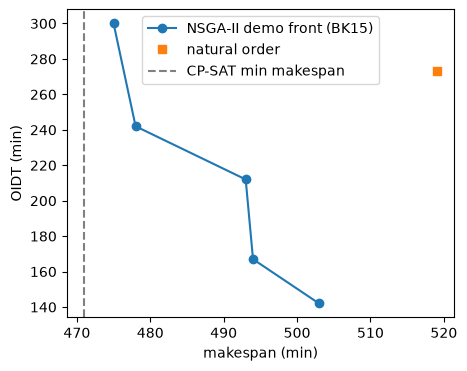

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(front['makespan'], front['oidt'], 'o-', label='NSGA-II demo front (BK15)')
nat = base['instances']['BK15']['natural']
ax.plot(nat['makespan'], nat['oidt'], 's', label='natural order')
ax.axvline(cp['makespan'], ls='--', c='gray', label='CP-SAT min makespan')
ax.set_xlabel('makespan (min)'); ax.set_ylabel('OIDT (min)'); ax.legend()
plt.show()

## Saved schedules

In [7]:
pd.read_csv(RESULTS / 'stage1-baseline' / 'bk15-natural-schedule.csv').head(15)

,g,orig_group,batch,p,product_name,s,stage_name,ST,CT,PT,assigned_k,assigned_l,assigned_resource
0,1,1,1,1,Product 1A,1,Preparation,0,5,5,NaN,1.0,Employee 1 (l=1)
1,2,2,1,1,Product 2A,1,Preparation,0,9,9,NaN,2.0,Employee 2 (l=2)
2,12,12,1,1,Product 12A,1,Defrost,0,80,80,NaN,NaN,NONE
3,1,1,1,1,Product 1A,2,Kneading,5,26,21,2.0,NaN,Kneader 2 (k=2)
4,2,2,1,1,Product 2A,2,Load kneader,9,11,2,NaN,1.0,Employee 1 (l=1)
5,2,2,1,1,Product 2A,3,Kneading,11,29,18,1.0,NaN,Kneader 1 (k=1)
6,1,1,1,1,Product 1A,3,Dividing,26,42,16,3.0,NaN,Divider (k=3)
7,2,2,1,1,Product 2A,4,Kneading disch.,29,31,2,NaN,1.0,Employee 1 (l=1)
8,3,3,1,1,Product 3A,1,Preparation,29,33,4,NaN,2.0,Employee 2 (l=2)
9,2,2,1,1,Product 2A,5,Dividing,31,40,9,NaN,1.0,Employee 1 (l=1)
